# Module 17 — The Mathematics of Transformers

This notebook builds a transformer piece by piece in NumPy and checks every claim of the
concept guide numerically: embeddings as one-hot products, scaled dot-product attention and
its heat-map, the variance of $QK^\top$ with and without $\sqrt{d_k}$, the softmax Jacobian
against finite differences, multi-head attention with a parameter counter that reproduces
GPT-2 small's 124M, the causal mask, sinusoidal and rotary positions, LayerNorm and a full
pre-norm block, decoding strategies and the KV cache, LoRA as a low-rank approximation,
and the geometry of embeddings.

Read the [concept guide](README.md) first, or keep it open alongside — every section here
mirrors a numbered section there. No framework is used anywhere: each object is a few
lines of NumPy, so you can see exactly what the maths does.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True, linewidth=120)

## 1. Tokens, embeddings and the residual stream

A token index $t$ becomes a vector by looking up row $t$ of the embedding matrix
$E \in \mathbb{R}^{V\times d}$ — which is the same as multiplying the one-hot vector $e_t$ by $E$:

$$x = e_t^\top E = E_{t,:}.$$

Layers then *add* to this vector (the residual stream), and at the end the tied unembedding
turns the final vector $h$ into logits $z = Eh$ — one dot product per vocabulary entry — and
a softmax turns the logits into next-token probabilities. We use the five-token vocabulary
of the guide.

In [2]:
def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)       # shift for numerical safety (softmax is shift-invariant)
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

vocab = ["the", "cat", "sat", "on", "mat"]
E = np.array([[ 1.0,  0.0, 0.5],
              [ 0.0,  1.0, 0.5],
              [-1.0,  0.0, 0.5],
              [ 0.0, -1.0, 0.5],
              [ 0.5,  0.5, 0.0]])
V, d = E.shape

tokens = np.array([0, 1, 2])                          # "the cat sat"
one_hot = np.eye(V)[tokens]                            # (n, V)
X = one_hot @ E                                        # (n, d): the initial residual stream
print("one-hot rows:\n", one_hot)
print("one_hot @ E equals E[tokens]:", np.allclose(X, E[tokens]))
print("residual stream X (one row per position):\n", X)

# the gradient of a lookup: only the rows that were used receive anything
dX = np.ones_like(X)                                   # pretend every output coordinate wants to grow
dE = one_hot.T @ dX
print("rows of E that receive a gradient:", np.flatnonzero(np.abs(dE).sum(axis=1)), "(tokens used:", tokens, ")")

# tied unembedding: logits are dot products with every row of E
h = np.array([0.8, 0.2, 0.5])                          # a final residual-stream vector
z = E @ h
p = softmax(z)
for tok, zz, pp in zip(vocab, z, p):
    print(f"  {tok:4s}  logit {zz:6.2f}   prob {pp:.3f}")
print("probabilities sum to", p.sum(), "; predicted next token:", vocab[int(np.argmax(p))])

one-hot rows:
 [[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]]
one_hot @ E equals E[tokens]: True
residual stream X (one row per position):
 [[ 1.   0.   0.5]
 [ 0.   1.   0.5]
 [-1.   0.   0.5]]
rows of E that receive a gradient: [0 1 2] (tokens used: [0 1 2] )
  the   logit   1.05   prob 0.371
  cat   logit   0.45   prob 0.204
  sat   logit  -0.55   prob 0.075
  on    logit   0.05   prob 0.136
  mat   logit   0.50   prob 0.214
probabilities sum to 0.9999999999999998 ; predicted next token: the


The lookup *is* a matrix product, which is why its gradient is so sparse: `dE` is zero in
the rows of tokens that did not occur. The logits reproduce the guide's hand calculation
$(1.05, 0.45, -0.55, 0.05, 0.5)$ and the model predicts "the" with probability 0.371, because
$h$ points most nearly along the first row of $E$. For GPT-2 small the same two objects are
$E \in \mathbb{R}^{50257\times768}$ and $h \in \mathbb{R}^{768}$.

## 2. Attention as a soft lookup

$$\operatorname{Attention}(Q, K, V) = \operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V ,$$

with the softmax taken **row-wise**, so each row of $P$ is a probability distribution over
the key positions and each output row is a convex combination of value rows. We first
reproduce the guide's three-token example by hand, then run a four-token example with
learned-looking projections and draw the attention weights.

scaled scores:
 [[0.7071 0.     0.7071]
 [0.     0.7071 0.7071]
 [0.7071 0.7071 1.4142]]
attention weights P (rows sum to one):
 [[0.4011 0.1978 0.4011]
 [0.1978 0.4011 0.4011]
 [0.2483 0.2483 0.5035]] 
row sums: [1. 1. 1.]
output O = P V:
 [[1.2033 0.7967]
 [0.7967 1.2033]
 [1.     1.    ]]

zero queries -> uniform weights: [0.3333 0.3333 0.3333]  output = mean of V: True

shapes: X (4, 8)  Q,K,V (4, 4)  P (4, 4)  O (4, 4)
P4:
 [[0.2742 0.207  0.267  0.2518]
 [0.2504 0.2319 0.2606 0.2571]
 [0.2735 0.2349 0.2634 0.2282]
 [0.257  0.2629 0.2566 0.2235]]


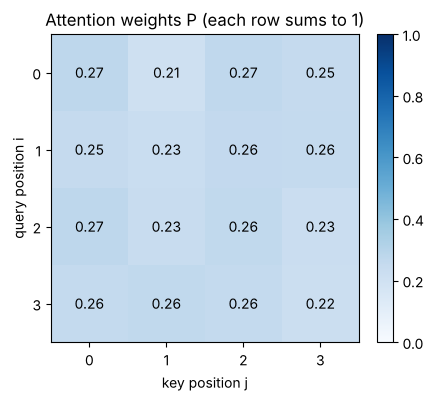

In [3]:
def attention(Q, K, V, mask=None):
    d_k = Q.shape[-1]
    S = Q @ K.T / np.sqrt(d_k)                      # scores (n_q, n_k)
    if mask is not None:
        S = np.where(mask, -np.inf, S)              # True = forbidden
    P = softmax(S, axis=-1)                         # one distribution per query
    return P @ V, P

# --- the guide's example: 3 tokens, d_k = 2
Q = K = np.array([[1., 0.], [0., 1.], [1., 1.]])
Vv = np.array([[2., 0.], [0., 2.], [1., 1.]])
O, P = attention(Q, K, Vv)
print("scaled scores:\n", Q @ K.T / np.sqrt(2))
print("attention weights P (rows sum to one):\n", P, "\nrow sums:", P.sum(axis=1))
print("output O = P V:\n", O)

# --- uniform scores give the plain mean of the values
O_uni, P_uni = attention(np.zeros((3, 2)), K, Vv)
print("\nzero queries -> uniform weights:", P_uni[0], " output = mean of V:", np.allclose(O_uni, Vv.mean(axis=0)))

# --- a 4-token example with projections
n, d_model, d_k = 4, 8, 4
X4 = rng.normal(size=(n, d_model))
W_Q, W_K, W_V = (rng.normal(size=(d_model, d_k)) / np.sqrt(d_model) for _ in range(3))
Q4, K4, V4 = X4 @ W_Q, X4 @ W_K, X4 @ W_V
O4, P4 = attention(Q4, K4, V4)
print("\nshapes: X", X4.shape, " Q,K,V", Q4.shape, " P", P4.shape, " O", O4.shape)
print("P4:\n", P4)

fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(P4, cmap="Blues", vmin=0, vmax=1)
for i in range(n):
    for j in range(n):
        ax.text(j, i, f"{P4[i, j]:.2f}", ha="center", va="center", color="black" if P4[i, j] < 0.6 else "white")
ax.set_xticks(range(n)); ax.set_yticks(range(n))
ax.set_xlabel("key position j"); ax.set_ylabel("query position i")
ax.set_title("Attention weights P (each row sums to 1)"); plt.colorbar(im, ax=ax, fraction=0.046); plt.show()

Row 1 of the hand example is $(0.401, 0.198, 0.401)$ and its output $(1.203, 0.797)$ — a
blend of the first and third values. Row 3 attends to everything about equally and returns
the centroid $(1, 1)$. In the heat-map each row is one query's distribution over keys; the
mixing weights change with the input, which is what makes attention a *data-dependent*
linear combination rather than a fixed layer.

**Try it yourself:** multiply `Q4` by 5 before calling `attention` (as if the scores were not
scaled). Watch the rows of `P4` turn into near one-hot vectors.

## 3. Why divide by $\sqrt{d_k}$

If the components of $q$ and $k$ are independent with mean 0 and variance 1, then
$\operatorname{Var}(q^\top k) = \sum_{i=1}^{d_k}\operatorname{Var}(q_ik_i) = d_k$, so the raw
scores have standard deviation $\sqrt{d_k}$ and $q^\top k/\sqrt{d_k}$ has variance exactly 1.
We measure this, and we measure what it does to the softmax: the mean entropy of attention
rows for 16 keys, with and without the scaling.

d_k =   4: Var(q.k) =    4.05 (theory 4),  Var(q.k/sqrt(d_k)) = 1.013   | mean attention entropy: raw 1.77, scaled 2.38 nats (uniform = 2.77)
d_k =  16: Var(q.k) =   15.92 (theory 16),  Var(q.k/sqrt(d_k)) = 0.995   | mean attention entropy: raw 0.91, scaled 2.37 nats (uniform = 2.77)
d_k =  64: Var(q.k) =   63.71 (theory 64),  Var(q.k/sqrt(d_k)) = 0.995   | mean attention entropy: raw 0.41, scaled 2.36 nats (uniform = 2.77)


d_k = 256: Var(q.k) =  258.42 (theory 256),  Var(q.k/sqrt(d_k)) = 1.009   | mean attention entropy: raw 0.19, scaled 2.36 nats (uniform = 2.77)


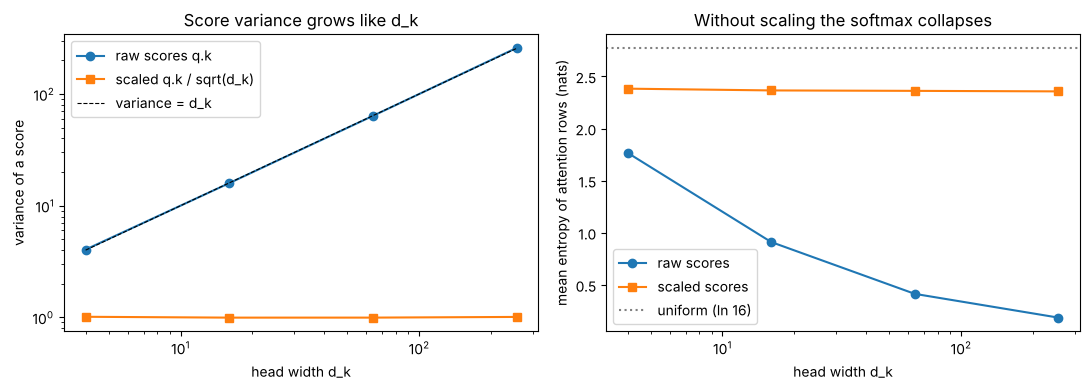


softmax of a score 1 above its competitor: [0.7311 0.2689]   8 above: [0.9997 0.0003]


In [4]:
def entropy(p, axis=-1):
    return -(p * np.log(np.clip(p, 1e-300, None))).sum(axis=axis)

ds = [4, 16, 64, 256]
n_keys, n_trials, n_samp = 16, 200, 20000
var_raw, var_scaled, H_raw, H_scaled = [], [], [], []
for dk in ds:
    q = rng.normal(size=(n_samp, dk)); k = rng.normal(size=(n_samp, dk))
    s = (q * k).sum(axis=1)
    var_raw.append(s.var()); var_scaled.append((s / np.sqrt(dk)).var())
    Hr, Hs = [], []
    for _ in range(n_trials):
        Qt = rng.normal(size=(n_keys, dk)); Kt = rng.normal(size=(n_keys, dk))
        S = Qt @ Kt.T
        Hr.append(entropy(softmax(S)).mean()); Hs.append(entropy(softmax(S / np.sqrt(dk))).mean())
    H_raw.append(np.mean(Hr)); H_scaled.append(np.mean(Hs))
    print(f"d_k = {dk:3d}: Var(q.k) = {var_raw[-1]:7.2f} (theory {dk}),  Var(q.k/sqrt(d_k)) = {var_scaled[-1]:.3f}"
          f"   | mean attention entropy: raw {H_raw[-1]:.2f}, scaled {H_scaled[-1]:.2f} nats (uniform = {np.log(n_keys):.2f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].loglog(ds, var_raw, "o-", label="raw scores q.k"); axes[0].loglog(ds, var_scaled, "s-", label="scaled q.k / sqrt(d_k)")
axes[0].loglog(ds, ds, "k--", lw=0.8, label="variance = d_k")
axes[0].set_xlabel("head width d_k"); axes[0].set_ylabel("variance of a score"); axes[0].set_title("Score variance grows like d_k"); axes[0].legend()
axes[1].semilogx(ds, H_raw, "o-", label="raw scores"); axes[1].semilogx(ds, H_scaled, "s-", label="scaled scores")
axes[1].axhline(np.log(n_keys), color="gray", ls=":", label="uniform (ln 16)")
axes[1].set_xlabel("head width d_k"); axes[1].set_ylabel("mean entropy of attention rows (nats)")
axes[1].set_title("Without scaling the softmax collapses"); axes[1].legend(); plt.tight_layout(); plt.show()

print("\nsoftmax of a score 1 above its competitor:", softmax(np.array([1., 0.])), "  8 above:", softmax(np.array([8., 0.])))

The measured variance of the raw scores tracks $d_k$ to within sampling error while the scaled
variance stays at $1.0$. The consequence is on the right: with $d_k = 256$ the raw-score
attention rows have an entropy near zero — essentially one-hot — while the scaled rows keep
most of the $\ln 16 = 2.77$ nats of a uniform distribution. A one-hot softmax has a Jacobian
of almost zero (next section), so without the $\sqrt{d_k}$ the queries and keys of a wide
head would barely learn.

## 4. The softmax Jacobian and attention gradients

$$\frac{\partial p_i}{\partial z_j} = p_i(\delta_{ij} - p_j), \qquad J = \operatorname{diag}(p) - pp^\top,
\qquad \frac{\partial L}{\partial z} = J^\top g = p\odot\big(g - (p^\top g)\mathbf 1\big).$$

We verify $J$ against central finite differences, watch it shrink as the softmax saturates
(and as the temperature drops), then check the full attention backward pass
$\partial V = P^\top G$, $\partial S = P\odot(GV^\top - \operatorname{rowsum}(GV^\top\odot P))$,
$\partial Q = \partial S\,K/\sqrt{d_k}$, $\partial K = \partial S^\top Q/\sqrt{d_k}$ the same way.

In [5]:
def softmax_jacobian(z):
    p = softmax(z)
    return np.diag(p) - np.outer(p, p)

def finite_difference_jacobian(f, z, eps=1e-6):
    J = np.zeros((f(z).size, z.size))
    for j in range(z.size):
        e = np.zeros_like(z); e[j] = eps
        J[:, j] = (f(z + e) - f(z - e)) / (2 * eps)
    return J

z = np.log(np.array([0.7, 0.2, 0.1]))               # logits whose softmax is exactly (0.7, 0.2, 0.1)
J = softmax_jacobian(z)
print("J for p = (0.7, 0.2, 0.1):\n", J)
print("row sums:", J.sum(axis=1), "  max |J - finite differences| = %.2e" % np.abs(J - finite_difference_jacobian(softmax, z)).max())
g = np.array([1., 0., 0.])
print("upstream g = (1,0,0)  ->  dL/dz = J^T g =", J.T @ g, " = p*(g - p.g) =", softmax(z) * (g - softmax(z) @ g))

# saturation: scale the logits up (equivalently, lower the temperature)
print("\nscale of logits (1/T)   p_max     largest |J| entry")
for scale in [0.5, 1, 2, 4, 8]:
    Js = softmax_jacobian(scale * z)
    print(f"{scale:16.1f}    {softmax(scale * z).max():.4f}    {np.abs(Js).max():.2e}")

# --- the attention backward pass, checked against finite differences
def attention_backward(Q, K, V, G):
    d_k = Q.shape[-1]
    S = Q @ K.T / np.sqrt(d_k); P = softmax(S)
    dV = P.T @ G
    dP = G @ V.T
    dS = P * (dP - (dP * P).sum(axis=1, keepdims=True))
    return dS @ K / np.sqrt(d_k), dS.T @ Q / np.sqrt(d_k), dV

Qa, Ka, Va = (rng.normal(size=(5, 3)) for _ in range(3))
G = rng.normal(size=(5, 3))                          # dL/dO for the scalar loss L = sum(G * O)
loss = lambda Q, K, V: (G * attention(Q, K, V)[0]).sum()
dQ, dK, dV = attention_backward(Qa, Ka, Va, G)
def fd_grad(f, M, eps=1e-6):
    out = np.zeros_like(M)
    for idx in np.ndindex(M.shape):
        Mp = M.copy(); Mp[idx] += eps; Mm = M.copy(); Mm[idx] -= eps
        out[idx] = (f(Mp) - f(Mm)) / (2 * eps)
    return out
print("\nattention backward vs finite differences:")
print("  dQ max error %.2e" % np.abs(dQ - fd_grad(lambda M: loss(M, Ka, Va), Qa)).max())
print("  dK max error %.2e" % np.abs(dK - fd_grad(lambda M: loss(Qa, M, Va), Ka)).max())
print("  dV max error %.2e" % np.abs(dV - fd_grad(lambda M: loss(Qa, Ka, M), Va)).max())

J for p = (0.7, 0.2, 0.1):
 [[ 0.21 -0.14 -0.07]
 [-0.14  0.16 -0.02]
 [-0.07 -0.02  0.09]]
row sums: [0. 0. 0.]   max |J - finite differences| = 5.50e-11
upstream g = (1,0,0)  ->  dL/dz = J^T g = [ 0.21 -0.14 -0.07]  = p*(g - p.g) = [ 0.21 -0.14 -0.07]

scale of logits (1/T)   p_max     largest |J| entry
             0.5    0.5229    2.49e-01
             1.0    0.7000    2.10e-01
             2.0    0.9074    8.40e-02
             4.0    0.9930    6.98e-03
             8.0    1.0000    4.46e-05

attention backward vs finite differences:
  dQ max error 3.18e-10
  dK max error 4.95e-10
  dV max error 3.81e-10


Every entry of $J$ matches the finite-difference estimate to about $10^{-10}$, and every row
sums to zero: adding a constant to all logits changes nothing, so the loss has no gradient
in that direction. Scaling the logits by 8 (temperature $1/8$) drives $p_{\max}$ to $0.9998$
and the largest Jacobian entry to about $4\times10^{-5}$ — five thousand times smaller than at
scale 1. The attention backward formulas also agree with finite differences; notice that
$\partial V = P^\top G$ needs no Jacobian at all, while $\partial Q$ and $\partial K$ pass
through $P\odot(\cdot)$ and vanish wherever a row of $P$ is saturated.

**Try it yourself:** set `z = np.log(np.array([0.98, 0.01, 0.01]))` and recompute `J`. What
is the largest entry now, and what does that mean for a classifier that is already confident?

## 5. Multi-head attention, parameters and FLOPs

$h$ heads of width $d_{\text{head}} = d/h$ each run attention in their own subspace; the
outputs are concatenated and mixed by $W_O$:

$$\operatorname{MHA}(X) = [H_1\,|\,\cdots\,|\,H_h]\,W_O, \qquad H_i = \operatorname{Attention}(XW_Q^{(i)}, XW_K^{(i)}, XW_V^{(i)}).$$

The attention sub-layer has $4d^2$ weights whatever $h$ is; the feed-forward sub-layer with
$d_{\text{ff}} = 4d$ adds $8d^2$; so a block has $12d^2$ weights. Per layer and sequence of $n$
tokens the FLOPs are about $24nd^2$ (weights) $+\ 4n^2d$ (attention) — the attention term wins
beyond $n = 6d$. We print shapes, count GPT-2 small, and plot the crossover.

X (6, 16) -> Q,K,V (6, 16) -> per head (4, 6, 4) -> scores (4, 6, 6) -> heads out (4, 6, 4) -> concat (6, 16) -> W_O -> (6, 16)
each head's rows sum to one: True
rank of one head's score matrix W_Q^(i) W_K^(i)^T: 4 (= d_head = 4 )
attention_weights     2,359,296
mlp_weights           4,718,592
block                 7,087,872
all_blocks           85,054,464
embeddings           39,383,808
unembedding                   0
total               124,439,808
12 d^2 = 7,077,888   -> GPT-2 small has 124.4M parameters

GPT-2 small at n = 1024: weights 1.45e+10 FLOPs, attention 3.22e+09 FLOPs (18% of the layer); crossover at n = 6d = 4608


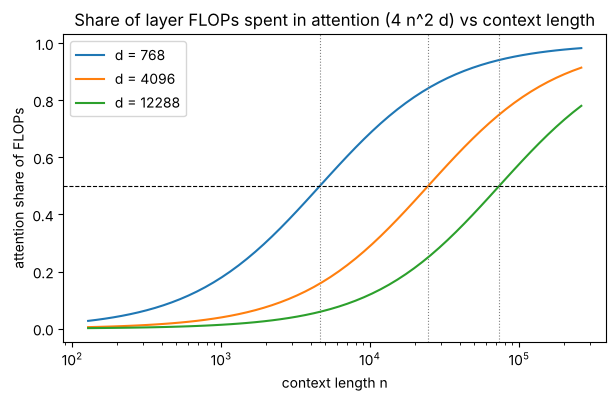

In [6]:
def multi_head_attention(X, W_Q, W_K, W_V, W_O, n_heads, mask=None, verbose=False):
    n, d = X.shape
    d_head = d // n_heads
    Q, K, V = X @ W_Q, X @ W_K, X @ W_V                            # (n, d) each
    split = lambda M: M.reshape(n, n_heads, d_head).transpose(1, 0, 2)   # -> (h, n, d_head)
    Qh, Kh, Vh = split(Q), split(K), split(V)
    S = Qh @ Kh.transpose(0, 2, 1) / np.sqrt(d_head)              # (h, n, n)
    if mask is not None:
        S = np.where(mask[None], -np.inf, S)
    P = softmax(S, axis=-1)
    Hh = P @ Vh                                                   # (h, n, d_head)
    concat = Hh.transpose(1, 0, 2).reshape(n, d)                  # (n, d)
    if verbose:
        print(f"X {X.shape} -> Q,K,V {Q.shape} -> per head {Qh.shape} -> scores {S.shape} -> heads out {Hh.shape} -> concat {concat.shape} -> W_O -> {(concat @ W_O).shape}")
    return concat @ W_O, P

n, d, h = 6, 16, 4
Xm = rng.normal(size=(n, d))
W_Q, W_K, W_V, W_O = (rng.normal(size=(d, d)) / np.sqrt(d) for _ in range(4))
out, P_heads = multi_head_attention(Xm, W_Q, W_K, W_V, W_O, h, verbose=True)
print("each head's rows sum to one:", np.allclose(P_heads.sum(axis=-1), 1))
print("rank of one head's score matrix W_Q^(i) W_K^(i)^T:", np.linalg.matrix_rank(W_Q[:, :d // h] @ W_K[:, :d // h].T), "(= d_head =", d // h, ")")

def count_params(d, n_layer, d_ff, vocab, n_ctx, tied=True):
    attn = 4 * d * d + 4 * d                   # W_Q, W_K, W_V, W_O and their biases
    mlp = d * d_ff + d_ff + d_ff * d + d       # W_1, b_1, W_2, b_2
    ln = 2 * (2 * d)                           # two LayerNorms (gain + bias each)
    block = attn + mlp + ln
    emb = vocab * d + n_ctx * d                # token table + learned position table
    unemb = 0 if tied else vocab * d
    total = n_layer * block + emb + unemb + 2 * d          # + final LayerNorm
    return dict(attention_weights=4 * d * d, mlp_weights=2 * d * d_ff, block=block,
                all_blocks=n_layer * block, embeddings=emb, unembedding=unemb, total=total)

gpt2 = count_params(d=768, n_layer=12, d_ff=3072, vocab=50257, n_ctx=1024)
for k_, v_ in gpt2.items():
    print(f"{k_:18s} {v_:>12,d}")
print("12 d^2 =", f"{12 * 768 ** 2:,d}", "  -> GPT-2 small has", f"{gpt2['total'] / 1e6:.1f}M parameters")

def flops_per_layer(n, d):
    return 24 * n * d ** 2, 4 * n ** 2 * d       # (weight FLOPs, attention FLOPs)

print("\nGPT-2 small at n = 1024: weights %.2e FLOPs, attention %.2e FLOPs (%.0f%% of the layer); crossover at n = 6d = %d"
      % (*flops_per_layer(1024, 768), 100 * flops_per_layer(1024, 768)[1] / sum(flops_per_layer(1024, 768)), 6 * 768))

ns = np.logspace(np.log10(128), np.log10(262144), 60)
for dd in [768, 4096, 12288]:
    w_, a_ = flops_per_layer(ns, dd)
    plt.semilogx(ns, a_ / (w_ + a_), label=f"d = {dd}")
    plt.axvline(6 * dd, color="gray", ls=":", lw=0.8)
plt.axhline(0.5, color="k", ls="--", lw=0.8)
plt.title("Share of layer FLOPs spent in attention (4 n^2 d) vs context length")
plt.xlabel("context length n"); plt.ylabel("attention share of FLOPs"); plt.legend(); plt.show()

The shapes tell the story: $Q$, $K$, $V$ are split into $h = 4$ heads of width $4$, each
producing its own $6\times6$ score matrix, and the concatenation restores width 16 before
$W_O$. Each head's score matrix has rank at most $d_{\text{head}}$ — a head is a low-rank
bilinear form on the residual stream. The counter gives $124{,}439{,}808$ parameters for GPT-2
small, with the blocks at $12d^2$ weights each and the token table alone 31 % of the model.
The dotted lines mark $n = 6d$: GPT-2 small (context 1024) never reaches it, while a
$d = 4096$ model at a 128k context spends 84 % of its layer FLOPs on attention.

## 6. Masking and causality

Adding $-\infty$ above the diagonal of the scores makes $e^{-\infty} = 0$, so position $i$
attends only to positions $\le i$ and the attention matrix is lower-triangular. The reward
is parallel training: the output at every position is a legitimate next-token prediction given
the true prefix (teacher forcing), and one forward pass yields $n$ loss terms,
$\mathcal L = -\tfrac1n\sum_i\log p(t_{i+1}\mid t_{\le i})$, perplexity $e^{\mathcal L}$.

mask (1 = forbidden):
 [[0 1 1 1 1 1]
 [0 0 1 1 1 1]
 [0 0 0 1 1 1]
 [0 0 0 0 1 1]
 [0 0 0 0 0 1]
 [0 0 0 0 0 0]]
entries of np.triu(ones) * -inf that are NaN: 21 -> use np.where(mask, -inf, S) instead

head 0 attention weights with the causal mask:
 [[1.     0.     0.     0.     0.     0.    ]
 [0.3794 0.6206 0.     0.     0.     0.    ]
 [0.4496 0.2016 0.3488 0.     0.     0.    ]
 [0.1073 0.383  0.1377 0.3719 0.     0.    ]
 [0.0631 0.3345 0.2302 0.2965 0.0758 0.    ]
 [0.1113 0.126  0.3125 0.1571 0.0764 0.2166]]
lower-triangular: True  rows sum to one: True  any NaN: False
positions whose output changed after editing token 5: [5]
same edit WITHOUT the mask changes positions: [0 1 2 3 4 5]


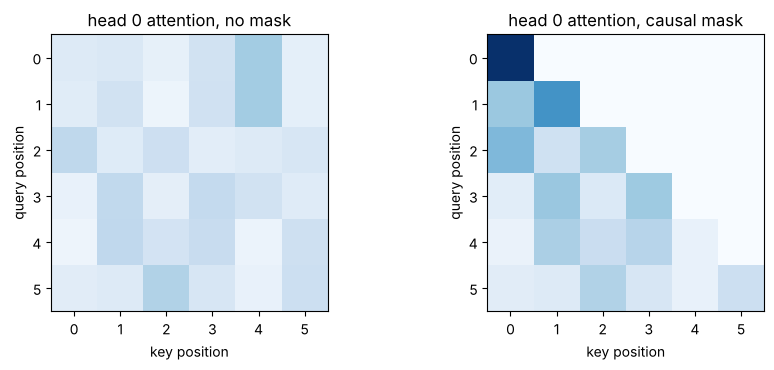


probability assigned to each true next token: [0.1537 0.034  0.6147 0.0034 0.0179]
mean cross-entropy 3.090 nats, perplexity 21.98; uniform over 50257 tokens would be 10.82 nats


In [7]:
def causal_mask(n):
    return np.triu(np.ones((n, n), dtype=bool), k=1)      # True above the diagonal = forbidden

n = 6
mask = causal_mask(n)
print("mask (1 = forbidden):\n", mask.astype(int))

# the classic bug: 0 * -inf is NaN
with np.errstate(invalid="ignore"):
    bad = np.triu(np.ones((n, n)), 1) * -np.inf
print("entries of np.triu(ones) * -inf that are NaN:", int(np.isnan(bad).sum()), "-> use np.where(mask, -inf, S) instead")

Xc = rng.normal(size=(n, d))
out_c, P_c = multi_head_attention(Xc, W_Q, W_K, W_V, W_O, h, mask=mask)
print("\nhead 0 attention weights with the causal mask:\n", P_c[0])
print("lower-triangular:", np.allclose(np.triu(P_c, 1), 0), " rows sum to one:", np.allclose(P_c.sum(-1), 1), " any NaN:", np.isnan(out_c).any())

# leakage test: change the LAST token and see which outputs move
Xc2 = Xc.copy(); Xc2[-1] += 10.0
out_c2, _ = multi_head_attention(Xc2, W_Q, W_K, W_V, W_O, h, mask=mask)
print("positions whose output changed after editing token 5:", np.flatnonzero(np.abs(out_c2 - out_c).max(axis=1) > 1e-12))
out_u2, _ = multi_head_attention(Xc2, W_Q, W_K, W_V, W_O, h)
out_u, _ = multi_head_attention(Xc, W_Q, W_K, W_V, W_O, h)
print("same edit WITHOUT the mask changes positions:", np.flatnonzero(np.abs(out_u2 - out_u).max(axis=1) > 1e-12))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, Pm, title in [(axes[0], multi_head_attention(Xc, W_Q, W_K, W_V, W_O, h)[1][0], "no mask"), (axes[1], P_c[0], "causal mask")]:
    ax.imshow(Pm, cmap="Blues", vmin=0, vmax=1); ax.set_title(f"head 0 attention, {title}")
    ax.set_xlabel("key position"); ax.set_ylabel("query position")
plt.tight_layout(); plt.show()

# teacher forcing: the loss over all positions in one pass
true_next = np.array([3, 1, 4, 0, 2])                     # targets for positions 0..4 of a 6-token sequence
logits = rng.normal(size=(5, V)) * 2
probs = softmax(logits)
p_correct = probs[np.arange(5), true_next]
loss = -np.log(p_correct).mean()
print("\nprobability assigned to each true next token:", p_correct)
print(f"mean cross-entropy {loss:.3f} nats, perplexity {np.exp(loss):.2f}; uniform over 50257 tokens would be {np.log(50257):.2f} nats")

With the mask, editing the last token changes only the last output; without it, every position
sees the edit — including positions that are supposed to be *predicting* that token. That is
the whole justification for training on all $n$ positions at once. The NaN line is the most
common attention bug in practice: build masks with `np.where`, never by multiplying by
$-\infty$.

**Try it yourself:** replace `-np.inf` in `multi_head_attention` by `-1e9`. The results are
identical — a large finite negative number is what most frameworks actually use.

## 7. Positional information: equivariance, sinusoids and RoPE

Attention without positions is **permutation-equivariant**: permuting the rows of $X$ permutes
the output rows identically, $\operatorname{Attn}(\Pi Q, \Pi K, \Pi V) = \Pi\operatorname{Attn}(Q, K, V)$.
Sinusoidal encodings fix this with a multi-resolution clock,

$$PE(pos, 2i) = \sin(pos\,\omega_i), \quad PE(pos, 2i+1) = \cos(pos\,\omega_i), \quad \omega_i = 10000^{-2i/d},$$

whose shift by $k$ is a fixed rotation $PE(pos+k) = R_k\,PE(pos)$. RoPE rotates the query and
key pairs themselves by $m\theta_i$, so that $q_m^\top k_n = q^\top R((n-m)\theta)\,k$ depends
only on the offset $n - m$.

Attn(Pi X) == Pi Attn(X): True  (no mask, no positions)

PE(0..2) for d = 4:
 [[ 0.      1.      0.      1.    ]
 [ 0.8415  0.5403  0.01    1.    ]
 [ 0.9093 -0.4161  0.02    0.9998]]
max |PE(pos+7) - R_7 PE(pos)| over pos = 0..56: 4.107825191113079e-15
R_k is orthogonal: True


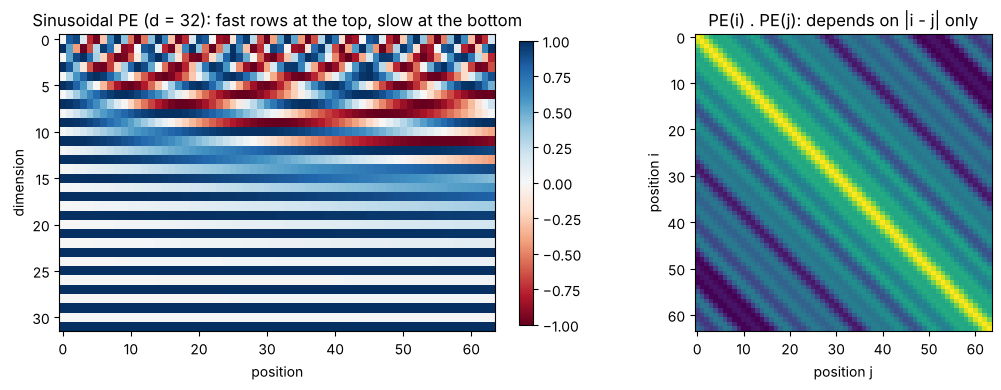

In [8]:
# --- permutation equivariance, numerically
perm = rng.permutation(n)
Pi = np.eye(n)[perm]                                   # permutation matrix: (Pi @ X)[i] = X[perm[i]]
out_perm, _ = multi_head_attention(Pi @ Xc, W_Q, W_K, W_V, W_O, h)
print("Attn(Pi X) == Pi Attn(X):", np.allclose(out_perm, Pi @ out_u), " (no mask, no positions)")

# --- sinusoidal encodings
def sinusoidal_pe(n_pos, d):
    pos = np.arange(n_pos)[:, None]
    i = np.arange(d // 2)[None, :]
    omega = 10000.0 ** (-2 * i / d)
    pe = np.zeros((n_pos, d))
    pe[:, 0::2] = np.sin(pos * omega)
    pe[:, 1::2] = np.cos(pos * omega)
    return pe

PE = sinusoidal_pe(64, 32)
print("\nPE(0..2) for d = 4:\n", sinusoidal_pe(3, 4))

def shift_matrix(k, d):
    # block-diagonal rotation R_k with PE(pos + k) = R_k PE(pos)
    omega = 10000.0 ** (-2 * np.arange(d // 2) / d)
    R = np.zeros((d, d))
    for i, w in enumerate(omega):
        c, s = np.cos(k * w), np.sin(k * w)
        R[2*i:2*i+2, 2*i:2*i+2] = [[c, s], [-s, c]]
    return R

k_shift = 7
R7 = shift_matrix(k_shift, 32)
print(f"max |PE(pos+{k_shift}) - R_{k_shift} PE(pos)| over pos = 0..56:", np.abs(PE[k_shift:] - PE[:-k_shift] @ R7.T).max())
print("R_k is orthogonal:", np.allclose(R7.T @ R7, np.eye(32)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
im = axes[0].imshow(PE.T, aspect="auto", cmap="RdBu", vmin=-1, vmax=1)
axes[0].set_xlabel("position"); axes[0].set_ylabel("dimension"); axes[0].set_title("Sinusoidal PE (d = 32): fast rows at the top, slow at the bottom")
plt.colorbar(im, ax=axes[0], fraction=0.03)
G = PE @ PE.T
axes[1].imshow(G, cmap="viridis"); axes[1].set_title("PE(i) . PE(j): depends on |i - j| only")
axes[1].set_xlabel("position j"); axes[1].set_ylabel("position i"); plt.tight_layout(); plt.show()

The permutation test passes to machine precision — shuffle the tokens and the outputs
shuffle with them, so a bare transformer cannot know word order. The sinusoidal table is a
set of clocks: the top rows cycle every few positions, the bottom rows barely move over 64
positions. The shift property holds exactly ($PE(pos+7) = R_7\,PE(pos)$ for every $pos$), and
the Gram matrix $PE(i)\cdot PE(j)$ is constant along diagonals — the encoding already "knows"
relative distance. RoPE makes that the *only* thing the scores know:

same content q, k at different absolute positions, same offset n - m = -2:
   positions (m, n) = (3, 1):  q_m . k_n = -0.106087
   positions (m, n) = (10, 8):  q_m . k_n = -0.106087
   positions (m, n) = (57, 55):  q_m . k_n = -0.106087
   positions (m, n) = (1000, 998):  q_m . k_n = -0.106087
offset changed to -3:    0.145078    offset 0:  0.666779 = raw q.k =  0.666779
score curve identical when computed around position 100 and around position 5: True


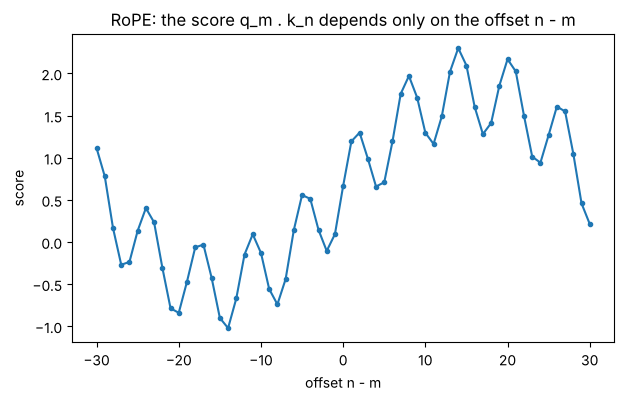

In [9]:
def rope(x, positions, base=10000.0):
    # x: (n, d) with d even; rotate pair i at position m by angle m * theta_i
    n_pos, d = x.shape
    theta = base ** (-2 * np.arange(d // 2) / d)                 # (d/2,)
    ang = positions[:, None] * theta[None, :]                    # (n, d/2)
    c, s = np.cos(ang), np.sin(ang)
    x1, x2 = x[:, 0::2], x[:, 1::2]
    out = np.empty_like(x)
    out[:, 0::2] = x1 * c - x2 * s
    out[:, 1::2] = x1 * s + x2 * c
    return out

d_r = 8
q = rng.normal(size=(1, d_r)); k = rng.normal(size=(1, d_r))
def rope_score(m, n_):
    return (rope(q, np.array([m])) @ rope(k, np.array([n_])).T).item()

print("same content q, k at different absolute positions, same offset n - m = -2:")
for m in [3, 10, 57, 1000]:
    print(f"   positions (m, n) = ({m}, {m - 2}):  q_m . k_n = {rope_score(m, m - 2): .6f}")
print("offset changed to -3:  ", f"{rope_score(10, 7): .6f}", "   offset 0:", f"{rope_score(10, 10): .6f}", "= raw q.k =", f"{(q @ k.T).item(): .6f}")

# the score as a function of the offset only: q_m^T k_n = q^T R((n-m) theta) k
offsets = np.arange(-30, 31)
scores = np.array([rope_score(100, 100 + o) for o in offsets])
scores_other_base = np.array([rope_score(5, 5 + o) for o in offsets])
print("score curve identical when computed around position 100 and around position 5:", np.allclose(scores, scores_other_base))
plt.plot(offsets, scores, "o-", ms=3)
plt.title("RoPE: the score q_m . k_n depends only on the offset n - m"); plt.xlabel("offset n - m"); plt.ylabel("score"); plt.show()

Moving the pair $(q, k)$ from positions $(3, 1)$ to $(1000, 998)$ leaves the score unchanged
to the last digit, while changing the offset by one changes it — exactly the statement
$q_m^\top k_n = q^\top R((n-m)\theta)\,k$. The curve is a sum of $d/2$ sinusoids in the offset
with frequencies $\theta_i$; the slowest ones only complete a cycle after thousands of
positions, which is why a model trained on short contexts has never seen the angles that
long contexts produce.

**Try it yourself:** change `base` to `500000.0` (Llama 3's choice) and re-plot. The curve
becomes smoother in the offset — the slow pairs rotate even more slowly.

## 8. LayerNorm, residuals and a full pre-norm block

LayerNorm acts on *one token's* vector, over its $d$ features:

$$\operatorname{LN}(x) = \gamma\odot\frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}} + \beta, \qquad
\mu = \tfrac1d\textstyle\sum_j x_j, \quad \sigma^2 = \tfrac1d\sum_j (x_j - \mu)^2 .$$

A pre-norm block is $X \leftarrow X + \operatorname{MHA}(\operatorname{LN}_1 X)$,
$X \leftarrow X + W_2\operatorname{GELU}(W_1\operatorname{LN}_2 X + b_1) + b_2$, with
$\operatorname{GELU}(u) = u\,\Phi(u)$. We implement all of it and run a two-layer, 4-head toy model.

In [10]:
from scipy.special import erf

def layer_norm(X, gamma=None, beta=None, eps=1e-5):
    mu = X.mean(axis=-1, keepdims=True)
    var = X.var(axis=-1, keepdims=True)
    Xn = (X - mu) / np.sqrt(var + eps)
    if gamma is not None:
        Xn = Xn * gamma + beta
    return Xn

def rms_norm(X, gamma=None, eps=1e-5):
    rms = np.sqrt((X ** 2).mean(axis=-1, keepdims=True) + eps)
    return X / rms if gamma is None else gamma * X / rms

def gelu(u):
    return 0.5 * u * (1.0 + erf(u / np.sqrt(2.0)))      # u * Phi(u), exact form

x = np.array([[2., 4., 6., 8.]])
print("LN(2,4,6,8) =", layer_norm(x, eps=0.0), "   mean %.1f, std %.1f" % (layer_norm(x, eps=0.0).mean(), layer_norm(x, eps=0.0).std()))
print("LN(10 x + 100) =", layer_norm(10 * x + 100, eps=0.0), " (scale and shift removed)")
print("RMSNorm(2,4,6,8) =", rms_norm(x, eps=0.0))
print("GELU(-1), GELU(1), GELU(2) =", gelu(np.array([-1., 1., 2.])))

def init_block(d, d_ff, rng):
    s = 1 / np.sqrt(d)
    return dict(W_Q=rng.normal(size=(d, d)) * s, W_K=rng.normal(size=(d, d)) * s, W_V=rng.normal(size=(d, d)) * s,
                W_O=rng.normal(size=(d, d)) * s, W_1=rng.normal(size=(d, d_ff)) * s, b_1=np.zeros(d_ff),
                W_2=rng.normal(size=(d_ff, d)) / np.sqrt(d_ff), b_2=np.zeros(d),
                g1=np.ones(d), be1=np.zeros(d), g2=np.ones(d), be2=np.zeros(d))

def transformer_block(X, p, n_heads, mask):
    a, _ = multi_head_attention(layer_norm(X, p["g1"], p["be1"]), p["W_Q"], p["W_K"], p["W_V"], p["W_O"], n_heads, mask)
    X = X + a                                                  # residual 1
    f = gelu(layer_norm(X, p["g2"], p["be2"]) @ p["W_1"] + p["b_1"]) @ p["W_2"] + p["b_2"]
    return X + f                                               # residual 2

n_tok, d_m, n_heads, d_ff, n_layers = 8, 32, 4, 128, 2
V_toy = 12
E_toy = rng.normal(size=(V_toy, d_m)) * 0.5
toks = rng.integers(0, V_toy, size=n_tok)
X = E_toy[toks] + sinusoidal_pe(n_tok, d_m)
blocks = [init_block(d_m, d_ff, rng) for _ in range(n_layers)]
norms = [np.linalg.norm(X, axis=1).mean()]
for p_ in blocks:
    X = transformer_block(X, p_, n_heads, causal_mask(n_tok))
    norms.append(np.linalg.norm(X, axis=1).mean())
logits = layer_norm(X) @ E_toy.T                               # final LN, tied unembedding
print("\ntokens:", toks)
print("mean residual-stream norm after embedding, block 1, block 2:", np.round(norms, 3))
print("logits shape", logits.shape, " next-token probabilities at the last position:", softmax(logits[-1]))
print("parameters in this toy model:", sum(v.size for p_ in blocks for v in p_.values()) + E_toy.size, " (12 d^2 per block =", 12 * d_m ** 2, ")")

LN(2,4,6,8) = [[-1.3416 -0.4472  0.4472  1.3416]]    mean 0.0, std 1.0
LN(10 x + 100) = [[-1.3416 -0.4472  0.4472  1.3416]]  (scale and shift removed)
RMSNorm(2,4,6,8) = [[0.3651 0.7303 1.0954 1.4606]]
GELU(-1), GELU(1), GELU(2) = [-0.1587  0.8413  1.9545]

tokens: [ 6  6 10  8  6  3  4  7]
mean residual-stream norm after embedding, block 1, block 2: [4.921 7.423 8.905]
logits shape (8, 12)  next-token probabilities at the last position: [0.0002 0.0318 0.0001 0.0001 0.0531 0.0291 0.0524 0.597  0.0033 0.     0.2317 0.0011]
parameters in this toy model: 25536  (12 d^2 per block = 12288 )


LayerNorm removes exactly two degrees of freedom (overall offset and scale) and keeps the
pattern; RMSNorm removes only the scale. In the pre-norm block the residual stream's norm
*grows* with depth — each block adds something to an untouched identity path — which is why
a final LayerNorm sits before the unembedding. The toy model has $12d^2 = 12{,}288$ weights
per block (plus biases and norms), exactly the accounting of Section 5.

## 9. Decoding strategies and the KV cache

Given logits $z$: greedy takes $\arg\max$; temperature samples from $\operatorname{softmax}(z/T)$;
top-$k$ keeps the $k$ largest; top-$p$ keeps the smallest set with cumulative mass $\ge p$;
beam search keeps the $B$ best partial sequences by total log-probability. The KV cache stores
$K$ and $V$ for every past token in every layer — $2\,L\,t\,h_{kv}d_{\text{head}}$ numbers.

greedy picks: A
T = 0.5: p = [0.842  0.114  0.0419 0.0021], entropy 0.538 nats
T = 1.0: p = [0.6095 0.2242 0.136  0.0303], entropy 1.014 nats
T = 2.0: p = [0.4344 0.2635 0.2052 0.0969], entropy 1.265 nats
top-k, k = 2: [0.7311 0.2689 0.     0.    ]
top-p, p = 0.9: cumulative [0.6095 0.8337 0.9697 1.    ] -> [0.6285 0.2312 0.1402 0.    ]


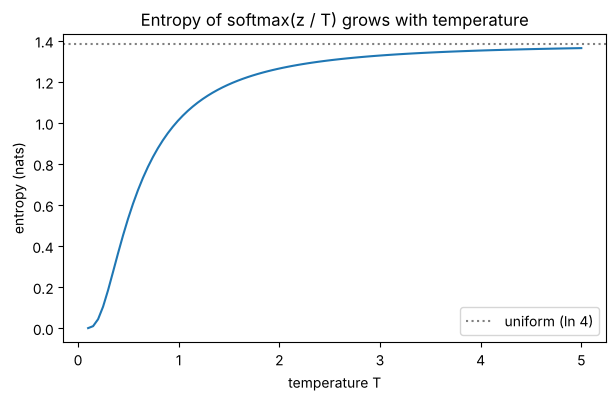


greedy sequence [0, 3, 3, 3, 3] log-prob -0.580
beam (B=3)      [0, 3, 3, 3, 3] log-prob -0.580  (beam >= greedy always)

KV cache:
  GPT-2 small, 1024 ctx         0.04 GiB  (    36 KiB per token)
  7B-class MHA, 8k ctx          4.00 GiB  (   512 KiB per token)
  70B-class GQA, 8k ctx         2.50 GiB  (   320 KiB per token)
  70B-class if MHA, 8k ctx     20.00 GiB  (  2560 KiB per token)


In [11]:
z = np.array([2.0, 1.0, 0.5, -1.0])
labels = ["A", "B", "C", "D"]

def temperature_probs(z, T):
    return softmax(z / T)

def top_k_probs(p, k):
    keep = np.argsort(-p)[:k]
    q = np.zeros_like(p); q[keep] = p[keep]
    return q / q.sum()

def top_p_probs(p, p_nucleus):
    order = np.argsort(-p)
    cum = np.cumsum(p[order])
    n_keep = int(np.searchsorted(cum, p_nucleus) + 1)          # smallest prefix with mass >= p
    q = np.zeros_like(p); q[order[:n_keep]] = p[order[:n_keep]]
    return q / q.sum()

p1 = temperature_probs(z, 1.0)
print("greedy picks:", labels[int(np.argmax(z))])
for T in [0.5, 1.0, 2.0]:
    pT = temperature_probs(z, T)
    print(f"T = {T}: p = {pT}, entropy {entropy(pT):.3f} nats")
print("top-k, k = 2:", top_k_probs(p1, 2))
print("top-p, p = 0.9: cumulative", np.cumsum(np.sort(p1)[::-1]), "->", top_p_probs(p1, 0.9))

Ts = np.linspace(0.1, 5, 100)
plt.plot(Ts, [entropy(temperature_probs(z, T)) for T in Ts])
plt.axhline(np.log(4), color="gray", ls=":", label="uniform (ln 4)")
plt.title("Entropy of softmax(z / T) grows with temperature"); plt.xlabel("temperature T"); plt.ylabel("entropy (nats)"); plt.legend(); plt.show()

# beam search on a toy model: next-token log-probs depend on the previous token only (a Markov chain)
logP = np.log(softmax(rng.normal(size=(4, 4)) * 2, axis=1))     # logP[prev, next]
def beam_search(logP, start, length, B):
    beams = [([start], 0.0)]
    for _ in range(length):
        cands = [(seq + [nxt], lp + logP[seq[-1], nxt]) for seq, lp in beams for nxt in range(4)]
        beams = sorted(cands, key=lambda c: -c[1])[:B]
    return beams
greedy_seq, greedy_lp = [0], 0.0
for _ in range(4):
    nxt = int(np.argmax(logP[greedy_seq[-1]])); greedy_lp += logP[greedy_seq[-1], nxt]; greedy_seq.append(nxt)
best = beam_search(logP, 0, 4, B=3)[0]
print("\ngreedy sequence", greedy_seq, "log-prob %.3f" % greedy_lp)
print("beam (B=3)     ", best[0], "log-prob %.3f  (beam >= greedy always)" % best[1])

def kv_cache_bytes(n_layer, n_tokens, n_kv_heads, d_head, bytes_per_number=2):
    return 2 * n_layer * n_tokens * n_kv_heads * d_head * bytes_per_number

print("\nKV cache:")
for name, cfg in [("GPT-2 small, 1024 ctx", dict(n_layer=12, n_tokens=1024, n_kv_heads=12, d_head=64)),
                  ("7B-class MHA, 8k ctx", dict(n_layer=32, n_tokens=8192, n_kv_heads=32, d_head=128)),
                  ("70B-class GQA, 8k ctx", dict(n_layer=80, n_tokens=8192, n_kv_heads=8, d_head=128)),
                  ("70B-class if MHA, 8k ctx", dict(n_layer=80, n_tokens=8192, n_kv_heads=64, d_head=128))]:
    b = kv_cache_bytes(**cfg)
    print(f"  {name:26s} {b / 2**30:7.2f} GiB  ({b / cfg['n_tokens'] / 1024:6.0f} KiB per token)")

Lowering the temperature to 0.5 squares the odds (0.61 → 0.84 for the top token) and halves
the entropy; raising it to 2 flattens the distribution. Top-$k$ and top-$p$ then cut the tail
and renormalise. Beam search never scores below greedy because greedy is one of the paths it
considers. The cache arithmetic reproduces the guide: 4 GiB for a 7B model at 8k context in
fp16, and a 70B model with grouped-query attention needs *less* cache (2.5 GiB) than the 7B
model, because only $h_{kv}d_{\text{head}} = 1024$ numbers per layer per token are stored.

**Try it yourself:** change `bytes_per_number` to 1 (an 8-bit cache) or `n_tokens` to
131072 (a 128k context) and see which models still fit in 80 GB next to their weights.

## 10. LoRA as low-rank approximation; quantisation error

LoRA writes the fine-tuned weight as $W = W_0 + \tfrac{\alpha}{r}BA$ with $B \in \mathbb{R}^{d\times r}$,
$A \in \mathbb{R}^{r\times d}$: $r(d_{\text{in}} + d_{\text{out}})$ trainable numbers instead of
$d_{\text{in}}d_{\text{out}}$. If the ideal update $\Delta W^\ast$ has singular values $\sigma_i$,
the best rank-$r$ adapter leaves error $\sqrt{\sum_{i>r}\sigma_i^2}$ (Eckart–Young, Module 03).
We build a true rank-4 update plus noise and watch the error curve, then measure absmax
quantisation error against its $s/\sqrt{12}$ prediction.

leading singular values of the update: [8.6188 8.0693 7.3728 7.0761 0.0622 0.0615] ...


max |measured error - Eckart-Young formula| = 5.33e-15


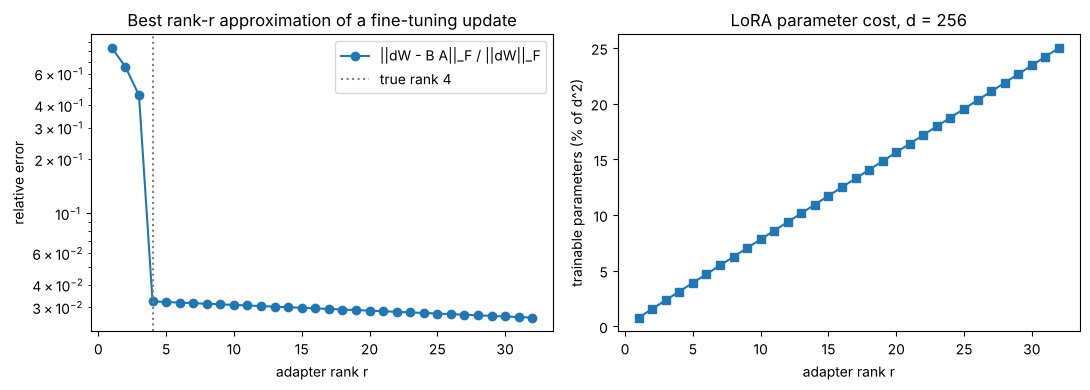

adapter path == merged weight: True
rank-8 adapter: 4,096 parameters = 6.25% of the 65,536-entry matrix;  for d = 4096: 65,536 vs 16,777,216 (0.39%)

absmax quantisation of 100k weights (std 0.02, absmax 0.0848):
  int8: scale s = 6.68e-04, max |error| = 3.34e-04 (bound s/2 = 3.34e-04), RMS error = 1.93e-04 (prediction s/sqrt(12) = 1.93e-04), relative to weight std: 1.0%
  int4: scale s = 1.21e-02, max |error| = 6.06e-03 (bound s/2 = 6.06e-03), RMS error = 3.50e-03 (prediction s/sqrt(12) = 3.50e-03), relative to weight std: 17.5%
  int4 with per-32-weight blocks: RMS error = 1.94e-03 (9.7% of weight std)


In [12]:
d_lora = 256
W0 = rng.normal(size=(d_lora, d_lora)) / np.sqrt(d_lora)
B_true = rng.normal(size=(d_lora, 4)); A_true = rng.normal(size=(4, d_lora))
dW_true = B_true @ A_true / np.sqrt(4 * d_lora) + 0.002 * rng.normal(size=(d_lora, d_lora))   # rank 4 + small noise

U, s, Vt = np.linalg.svd(dW_true)
print("leading singular values of the update:", s[:6], "...")
ranks = np.arange(1, 33)
err = [np.linalg.norm(dW_true - (U[:, :r] * s[:r]) @ Vt[:r]) for r in ranks]
ey = [np.sqrt((s[r:] ** 2).sum()) for r in ranks]
print("max |measured error - Eckart-Young formula| = %.2e" % np.abs(np.array(err) - np.array(ey)).max())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogy(ranks, np.array(err) / np.linalg.norm(dW_true), "o-", label="||dW - B A||_F / ||dW||_F")
axes[0].axvline(4, color="gray", ls=":", label="true rank 4"); axes[0].set_xlabel("adapter rank r"); axes[0].set_ylabel("relative error")
axes[0].set_title("Best rank-r approximation of a fine-tuning update"); axes[0].legend()
params_full = d_lora ** 2
axes[1].plot(ranks, ranks * 2 * d_lora / params_full * 100, "s-")
axes[1].set_xlabel("adapter rank r"); axes[1].set_ylabel("trainable parameters (% of d^2)"); axes[1].set_title(f"LoRA parameter cost, d = {d_lora}")
plt.tight_layout(); plt.show()

# merging: the adapted layer and the merged weight give identical outputs
r, alpha = 8, 16
B_ad, A_ad = U[:, :r] * np.sqrt(s[:r]), (np.sqrt(s[:r])[:, None] * Vt[:r]) * r / alpha
x = rng.normal(size=(5, d_lora))
y_adapter = x @ W0.T + (x @ A_ad.T) @ B_ad.T * (alpha / r)
W_merged = W0 + (alpha / r) * B_ad @ A_ad
print("adapter path == merged weight:", np.allclose(y_adapter, x @ W_merged.T))
print(f"rank-{r} adapter: {r * 2 * d_lora:,d} parameters = {r * 2 * d_lora / d_lora**2:.2%} of the {d_lora**2:,d}-entry matrix;"
      f"  for d = 4096: {8 * 2 * 4096:,d} vs {4096**2:,d} ({8 * 2 * 4096 / 4096**2:.2%})")

# absmax quantisation
def quantize_absmax(w, bits):
    qmax = 2 ** (bits - 1) - 1
    s = np.abs(w).max() / qmax
    q = np.round(w / s)
    return q, s

w = rng.normal(size=100_000) * 0.02                              # realistic weight magnitudes
print("\nabsmax quantisation of 100k weights (std 0.02, absmax %.4f):" % np.abs(w).max())
for bits in [8, 4]:
    q, s_ = quantize_absmax(w, bits)
    e = w - q * s_
    print(f"  int{bits}: scale s = {s_:.2e}, max |error| = {np.abs(e).max():.2e} (bound s/2 = {s_/2:.2e}), RMS error = {e.std():.2e} (prediction s/sqrt(12) = {s_/np.sqrt(12):.2e}), relative to weight std: {e.std()/w.std():.1%}")
blocks_ = w.reshape(-1, 32)                                      # block-wise scales: 32 weights per scale
e_blk = np.concatenate([(b - quantize_absmax(b, 4)[0] * quantize_absmax(b, 4)[1]) for b in blocks_])
print(f"  int4 with per-32-weight blocks: RMS error = {e_blk.std():.2e} ({e_blk.std()/w.std():.1%} of weight std)")

The error curve drops to the noise floor at $r = 4$ — the true rank — and sits exactly on the
Eckart–Young formula; beyond that, extra rank buys nothing but parameters. A rank-8 adapter on
a $4096\times4096$ matrix is 0.39 % of its size, and the merged weight reproduces the adapter
path to machine precision, so inference costs nothing extra. Quantisation error behaves as
uniform rounding noise: RMS $s/\sqrt{12}$, so int8 is at 1 % of the weights' typical size
while a single int4 scale for the whole tensor is at 17 %; small blocks with their own scales
cut the int4 error roughly in half (about 10 %), which — together with outlier handling — is the trick behind 4-bit inference.

## 11. Embedding geometry: anisotropy and linear probes

Hidden states of real transformers share a large common component, so the cosine similarity
between *unrelated* tokens is far above zero (anisotropy); centring fixes it. A linear probe
— logistic regression from frozen hidden states to a label — tests whether a concept is a
*direction* in the representation. We simulate both effects.

mean cosine between unrelated tokens: raw 0.882, after centring -0.003


linear probe held-out accuracy: 0.91;  cosine(probe direction, true concept direction) = 0.828


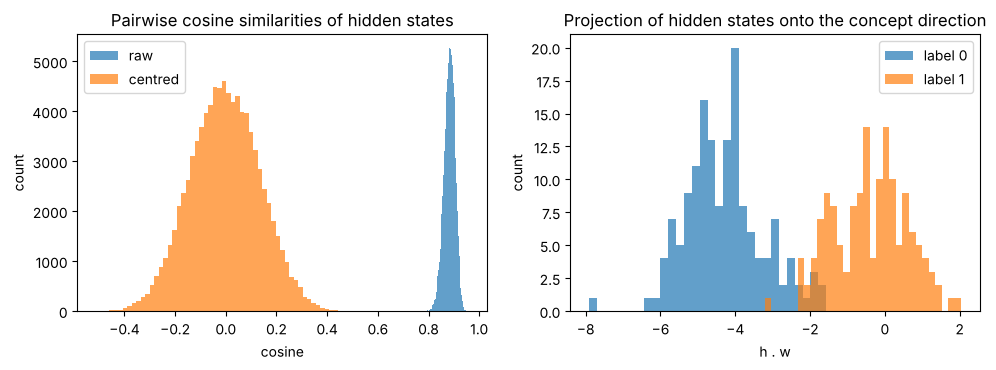


cos(u, v) = 0.000;  after adding (3,3,3) to both: 0.971;  after centring again: -1.000


In [13]:
from sklearn.linear_model import LogisticRegression

def cosine_matrix(H):
    Hn = H / np.linalg.norm(H, axis=1, keepdims=True)
    return Hn @ Hn.T

n_tok, d_h = 300, 64
labels_c = rng.integers(0, 2, size=n_tok)
concept_dir = rng.normal(size=d_h); concept_dir /= np.linalg.norm(concept_dir)
common = 3.0 * rng.normal(size=d_h)                                # the shared offset every token carries
H = rng.normal(size=(n_tok, d_h)) + common + 4.0 * (labels_c[:, None] - 0.5) * concept_dir   # isotropic noise + anisotropy + a concept direction

C_raw = cosine_matrix(H); C_cen = cosine_matrix(H - H.mean(axis=0))
off = ~np.eye(n_tok, dtype=bool)
print(f"mean cosine between unrelated tokens: raw {C_raw[off].mean():.3f}, after centring {C_cen[off].mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].hist(C_raw[off], bins=60, alpha=0.7, label="raw"); axes[0].hist(C_cen[off], bins=60, alpha=0.7, label="centred")
axes[0].set_title("Pairwise cosine similarities of hidden states"); axes[0].set_xlabel("cosine"); axes[0].set_ylabel("count"); axes[0].legend()

# linear probe: can logistic regression read the concept off the hidden state?
idx = rng.permutation(n_tok); tr, te = idx[:200], idx[200:]
probe = LogisticRegression(max_iter=2000).fit(H[tr], labels_c[tr])
acc = probe.score(H[te], labels_c[te])
w_hat = probe.coef_[0] / np.linalg.norm(probe.coef_)
print(f"linear probe held-out accuracy: {acc:.2f};  cosine(probe direction, true concept direction) = {abs(w_hat @ concept_dir):.3f}")
proj = H @ concept_dir
axes[1].hist(proj[labels_c == 0], bins=30, alpha=0.7, label="label 0"); axes[1].hist(proj[labels_c == 1], bins=30, alpha=0.7, label="label 1")
axes[1].set_title("Projection of hidden states onto the concept direction"); axes[1].set_xlabel("h . w"); axes[1].set_ylabel("count"); axes[1].legend()
plt.tight_layout(); plt.show()

# the guide's 3-D example
u, v = np.array([1., 0, 0]), np.array([0, 1., 0])
print("\ncos(u, v) = %.3f;  after adding (3,3,3) to both: %.3f;  after centring again: %.3f"
      % (u @ v, (u + 3) @ (v + 3) / np.linalg.norm(u + 3) / np.linalg.norm(v + 3),
         float(cosine_matrix(np.stack([u + 3, v + 3]) - np.stack([u + 3, v + 3]).mean(axis=0))[0, 1])))

The shared offset makes every pair of tokens look alike (mean cosine around 0.9); subtracting
the mean vector restores a distribution centred on zero, and *then* cosine similarity means
something. The probe recovers the planted concept direction almost exactly and classifies
held-out tokens with high accuracy — the operational meaning of "the concept is linearly
represented". Both diagnostics are routine when building retrieval indexes or interpreting
hidden states.

## Summary

- Embedding lookup is a one-hot matrix product; with tied weights, next-token logits are dot
  products of the residual stream with every token's embedding.
- Attention is $\operatorname{softmax}(QK^\top/\sqrt{d_k})V$: a data-dependent convex
  combination of values; uniform scores give the plain mean.
- Scores have variance $d_k$ at initialisation; dividing by $\sqrt{d_k}$ keeps the softmax
  soft and the gradients alive.
- The softmax Jacobian is $\operatorname{diag}(p) - pp^\top$; its rows sum to zero and it
  vanishes under saturation. Attention's backward pass follows from it in four lines.
- A block has $12d^2$ weights and costs $24nd^2 + 4n^2d$ FLOPs per layer; GPT-2 small's
  $124{,}439{,}808$ parameters follow from its config; attention dominates beyond $n = 6d$.
- The causal mask ($-\infty$ above the diagonal, built with `np.where`) makes every position a
  valid next-token prediction, so one pass gives $n$ loss terms.
- Attention is permutation-equivariant; sinusoidal encodings shift by rotations, RoPE makes
  the score a function of the relative offset only.
- LayerNorm normalises each token over its features; pre-norm residual blocks let the stream
  grow while the sub-layers see unit-scale inputs.
- Temperature, top-$k$, top-$p$ and beam search trade accuracy for diversity; the KV cache
  costs $2Lt\,h_{kv}d_{\text{head}}$ numbers — 4 GiB for a 7B model at 8k context in fp16.
- LoRA is a learned truncated SVD of the weight update; merged, it costs nothing at inference.
  Quantisation error is uniform rounding noise with RMS $s/\sqrt{12}$.
- Hidden states are anisotropic — centre before comparing cosines — and linear probes test
  whether a concept is a direction.

## Next: open `exercises.ipynb`

Twelve exercises with instant self-checks, from embedding lookup to a single-head causal
transformer trained with hand-derived gradients.